SETAC Europe Theme 3: Webinar registrations and member groups
Joel Aduba | Exploratory Python analysis

Analysis period: 1 October 2025 to 30 September 2026, inclusive. This is a twelve-month window ending at Busola's cut-off. It replaces the earlier September–August proposal for this notebook.
Questions to answer
1. How many identifiable Europe members had recorded membership coverage during this year? What is their breakdown by membership class, paid/free category, grade and sector?
2. Which supplied webinar files contain registrations booked within the year, and how much of the supplied collection does that represent?
3. How many eligible members registered for at least one of those webinars? How many different webinars did they register for?
4. Do recorded registration rates differ between free and paid members, and between students, recent graduates, professionals and sectors?
5. Are a small number of members registering repeatedly, or is participation spread across members?
6. How do registrations vary by month and webinar? How much of each webinar's registration list can be linked to our member population?
7. Do differences remain when we show members' differing lengths of membership coverage?
8. Which data gaps or assumptions limit the conclusions we can draw?
What these measures mean: the files do not contain an Attended field. This notebook measures recorded registrations, not verified attendance, viewing, satisfaction or benefit received. Dates refer to when bookings were made, not necessarily when webinars took place. Four supplied files contain bookings in this window; the collection is not confirmed to cover every webinar offered.

We use Busola's valid_subscriptions and person_details as the starting point. Her reconstructed coverage and historical class/grade assumptions still need checking against the SETAC Q&A. Results are exploratory until those assumptions are agreed. This notebook does not recalculate renewal outcomes.

1. Imports packages and set the analysis dates

Run cells in order. The main packages are pandas, NumPy, matplotlib and seaborn; openpyxl reads Excel files. If imports fail, uncomment the installation line in your own notebook environment, run it once, then restart the kernel.

The end of the window is represented internally as 1 October 2026, exclusive, so bookings at any time on 30 September are included.

In [145]:
# If needed, run once in Jupyter, then restart the kernel:
%pip install pandas numpy matplotlib seaborn openpyxl

from pathlib import Path
from io import BytesIO
import sys
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ANALYSIS_START = pd.Timestamp('2025-10-01')
ANALYSIS_END_EXCLUSIVE = pd.Timestamp('2026-10-01')
ANALYSIS_END = ANALYSIS_END_EXCLUSIVE - pd.Timedelta(days=1)
WINDOW_DAYS = (ANALYSIS_END_EXCLUSIVE - ANALYSIS_START).days

pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 85)
sns.set_theme(style='whitegrid', context='notebook')

print(f'Analysis: {ANALYSIS_START:%d %B %Y} to {ANALYSIS_END:%d %B %Y}')
print(f'Window length: {WINDOW_DAYS} days')
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Analysis: 01 October 2025 to 30 September 2026
Window length: 365 days
Python: 3.13.2 | pandas: 3.0.6


2. Locates and imports the relevant files

This notebook must be beside Busola's workbook and the original SETAC Europe Project Dataf file , or use your existing extracted Events/Webinars folder. The code reads the ZIP directly if no extracted webinar folder is found. It does not extract or modify source files.

The workbook can be named SETAC_Theme1_master_tables.xlsx or Copy of SETAC_Theme1_master_tables.xlsx.

Only two master sheets are loaded. We do not join webinar rows to tables A, B or C.

In [146]:
# Optional: replace None with your own Path(...) if automatic discovery fails.
MASTER_PATH = None
WEBINAR_DIR = None
RAW_ZIP_PATH = None

working_dir = Path.cwd().resolve()
project_dir = next(
    (p for p in [working_dir, *working_dir.parents] if (p / '.git').exists()),
    working_dir
)
search_locations = list(dict.fromkeys([
    working_dir, project_dir, working_dir.parent,
    project_dir / 'Fourth Rev - Data Edited',
    project_dir / 'Fourth Rev - Data'
]))

if MASTER_PATH is None:
    master_candidates = list(dict.fromkeys(
        base / name
        for base in search_locations
        for name in ['SETAC_Theme1_master_tables.xlsx',
                     'Copy of SETAC_Theme1_master_tables.xlsx']
        if (base / name).is_file()
    ))
    if len(master_candidates) != 1:
        raise FileNotFoundError(
            f'Expected one master workbook; found {len(master_candidates)}. '
            'Set MASTER_PATH to the agreed workbook explicitly.'
        )
    MASTER_PATH = master_candidates[0]
MASTER_PATH = Path(MASTER_PATH)

if WEBINAR_DIR is None:
    WEBINAR_DIR = next(
        (base / 'Events' / 'Webinars' for base in search_locations
         if (base / 'Events' / 'Webinars').is_dir()), None
    )
if RAW_ZIP_PATH is None:
    RAW_ZIP_PATH = next(
        (base / 'SETAC Europe Project Data.zip' for base in search_locations
         if (base / 'SETAC Europe Project Data.zip').is_file()), None
    )
if WEBINAR_DIR is None and RAW_ZIP_PATH is None:
    raise FileNotFoundError('Set WEBINAR_DIR or RAW_ZIP_PATH to your webinar source.')

master_sheets = pd.read_excel(
    MASTER_PATH, sheet_name=['valid_subscriptions', 'person_details']
)
subscriptions = master_sheets['valid_subscriptions'].copy()
people = master_sheets['person_details'].copy()

print('Master workbook:', MASTER_PATH.name)
print('Webinar source:', 'Extracted folder' if WEBINAR_DIR is not None else 'Original ZIP')
display(pd.DataFrame({
    'table': ['valid_subscriptions', 'person_details'],
    'rows': [len(subscriptions), len(people)],
    'columns': [subscriptions.shape[1], people.shape[1]]
}))
display(subscriptions.head(3))
display(people.head(3))


Master workbook: SETAC_Theme1_master_tables.xlsx
Webinar source: Extracted folder


,table,rows,columns
0,valid_subscriptions,16046,31
1,person_details,28922,10


,contact_id,subscription_id,contact_type,contact_status,status,member_class,cancelled_at,price,duration,plan,grade,sub_status,...,migrated_record,exclude_reason,n_terms,record_id,term_no,running_max_end,previous_max_end,extends_cover,new_spell,spell_no,spell_start,spell_first_migrated
0,000750DD-0E8A-4276-B8B013E4B5AE4567,A971E0F6-6FC0-4060-A85910C46471556D_t1,Contact,Active,Active,Full,NaT,40.0,1 year,"Annual Europe, standard",Student Membership,NaN,...,True,KEPT,4,A971E0F6-6FC0-4060-A85910C46471556D,1,2024-04-04 06:00:00,NaT,True,True,1,2023-04-05,True
1,000750DD-0E8A-4276-B8B013E4B5AE4567,A971E0F6-6FC0-4060-A85910C46471556D_t2,Contact,Active,Active,Full,NaT,40.0,1 year,"Annual Europe, standard",Student Membership,NaN,...,True,KEPT,4,A971E0F6-6FC0-4060-A85910C46471556D,2,2025-04-04 12:00:00,2024-04-04 06:00:00,True,False,1,2023-04-05,True
2,000750DD-0E8A-4276-B8B013E4B5AE4567,A971E0F6-6FC0-4060-A85910C46471556D_t3,Contact,Active,Active,Full,NaT,40.0,1 year,"Annual Europe, standard",Student Membership,NaN,...,True,KEPT,4,A971E0F6-6FC0-4060-A85910C46471556D,3,2026-04-04 18:00:00,2025-04-04 12:00:00,True,False,1,2023-04-05,True


,contact_id,country,graduation_date,sector,retired_flag,mentor,grad_is_default,n_topics,geo_unit,fee_band
0,000750DD-0E8A-4276-B8B013E4B5AE4567,Portugal,2026-09-30,Academia,0.0,False,False,3,SETAC Europe,Standard
1,00094A1F-9539-44DF-9B22339350548FA4,United States,2024-12-13,Academia,0.0,False,False,1,SETAC North America,Standard
2,00106011-A0C2-42D2-BC06CB1ED87CA8AA,Unknown,2018-06-01,Unknown,NaN,False,True,1,Unknown,Unknown


2.1 Check identifiers, dates and source structure

Repeated Contact IDs are expected in the subscription table: they describe different terms for one person. person_details should contain only one row per contact. We retain the original subscription IDs and never deduplicate subscription histories by Contact ID.

We normalise IDs as trimmed uppercase text. Invalid dates and records are reported before filtering. In this notebook, a subscription end date is treated as the last covered calendar day, with no extra lapsed/grace month added. This is an explicit exploratory convention to confirm with Busola's work.

In [147]:
def clean_contact_id(series):
    return series.astype('string').str.strip().str.upper().replace('', pd.NA)

required_sub = {'contact_id', 'subscription_id', 'record_id', 'member_class',
                'grade', 'start_date', 'end_date'}
required_people = {'contact_id', 'country', 'sector', 'mentor', 'grad_is_default'}
assert required_sub.issubset(subscriptions.columns), 'Required subscription columns missing.'
assert required_people.issubset(people.columns), 'Required person columns missing.'

subscriptions['contact_id'] = clean_contact_id(subscriptions['contact_id'])
people['contact_id'] = clean_contact_id(people['contact_id'])
for col in ['start_date', 'end_date']:
    subscriptions[col] = pd.to_datetime(subscriptions[col], errors='coerce')

valid_interval = (
    subscriptions['contact_id'].notna()
    & subscriptions['start_date'].notna()
    & subscriptions['end_date'].notna()
    & subscriptions['end_date'].gt(subscriptions['start_date'])
)
subscription_checks = pd.DataFrame({
    'check': ['Subscription rows', 'Distinct nonblank member IDs',
              'Missing subscription Contact IDs', 'Duplicate term IDs',
              'Unusable intervals', 'Duplicate person Contact IDs'],
    'count': [len(subscriptions), subscriptions['contact_id'].nunique(),
              subscriptions['contact_id'].isna().sum(),
              subscriptions['subscription_id'].duplicated().sum(),
              (~valid_interval).sum(), people['contact_id'].duplicated().sum()]
})
display(subscription_checks)
assert people['contact_id'].notna().all() and people['contact_id'].is_unique
assert subscriptions['subscription_id'].is_unique, 'Resolve duplicate term IDs first.'

excluded_intervals = subscriptions.loc[~valid_interval].copy()
subs_valid = subscriptions.loc[valid_interval].copy()
subs_valid['coverage_start'] = subs_valid['start_date'].dt.normalize()
subs_valid['coverage_end_exclusive'] = (
    subs_valid['end_date'].dt.normalize() + pd.Timedelta(days=1)
)


,check,count
0,Subscription rows,16046
1,Distinct nonblank member IDs,11141
2,Missing subscription Contact IDs,0
3,Duplicate term IDs,0
4,Unusable intervals,0
5,Duplicate person Contact IDs,0


3. Build the Theme 3 member population

Include every identifiable person with at least one retained Europe subscription term overlapping the year. This keeps people whose memberships ended before September 2026, and people who joined during the year.

For the first comparisons, each person is classified by the membership covering their first covered day in this window. That is a baseline label, not a claim that they held the same class or grade for the whole year. Where multiple classes or grades overlap on that day, the baseline is labelled Ambiguous rather than choosing one without evidence. Later class/grade variation is flagged.

Coverage days are calculated from the union of the person's recorded intervals, so overlapping terms are not counted twice. Current profile attributes such as sector are used with their historical limitations.

In [148]:
period_terms = subs_valid.loc[
    subs_valid['coverage_start'].lt(ANALYSIS_END_EXCLUSIVE)
    & subs_valid['coverage_end_exclusive'].gt(ANALYSIS_START)
].copy()
period_terms['window_start'] = period_terms['coverage_start'].clip(lower=ANALYSIS_START)
period_terms['window_end_exclusive'] = period_terms['coverage_end_exclusive'].clip(
    upper=ANALYSIS_END_EXCLUSIVE
)
period_terms['member_class'] = period_terms['member_class'].astype('string').str.strip()
period_terms['grade_short'] = (
    period_terms['grade'].astype('string')
    .str.replace(r'\s+Membership$', '', regex=True).str.strip()
)

def one_value_or_ambiguous(series):
    values = series.dropna().unique()
    if len(values) == 0:
        return 'Unknown'
    return str(values[0]) if len(values) == 1 else 'Ambiguous'

def union_coverage_days(frame):
    intervals = sorted(zip(frame['window_start'], frame['window_end_exclusive']))
    total = 0
    start, end = intervals[0]
    for next_start, next_end in intervals[1:]:
        if next_start <= end:
            end = max(end, next_end)
        else:
            total += (end - start).days
            start, end = next_start, next_end
    return total + (end - start).days

member_rows = []
for contact_id, terms in period_terms.groupby('contact_id', sort=True):
    first_day = terms['window_start'].min()
    baseline = terms.loc[
        terms['coverage_start'].le(first_day)
        & terms['coverage_end_exclusive'].gt(first_day)
    ]
    member_rows.append({
        'contact_id': contact_id,
        'first_covered_day': first_day,
        'last_covered_day': terms['window_end_exclusive'].max() - pd.Timedelta(days=1),
        'member_class_baseline': one_value_or_ambiguous(baseline['member_class']),
        'grade_baseline': one_value_or_ambiguous(baseline['grade_short']),
        'class_varies_in_window': terms['member_class'].nunique() > 1,
        'grade_varies_in_window': terms['grade_short'].nunique() > 1,
        'subscription_terms_in_window': len(terms),
        'covered_days': union_coverage_days(terms)
    })
members = pd.DataFrame(member_rows)
assert not members.empty, 'No members overlap the chosen period.'
assert members['contact_id'].is_unique
assert members['covered_days'].between(1, WINDOW_DAYS).all()

members['paid_or_free_baseline'] = members['member_class_baseline'].map({
    'Free': 'Free', 'Full': 'Paid', 'Explorer': 'Paid',
    'Ambiguous': 'Ambiguous', 'Unknown': 'Unknown'
}).fillna('Unknown')
members['membership_months_equivalent'] = members['covered_days'] / (WINDOW_DAYS / 12)

members = members.merge(people, on='contact_id', how='left', validate='one_to_one',
                        indicator='profile_link')
display(members['profile_link'].value_counts().rename_axis('profile_link').reset_index(name='members'))
for col in ['sector', 'country']:
    members[col] = members[col].astype('string').str.strip().replace('', pd.NA).fillna('Unknown')

print(f'Eligible members in the year: {len(members):,}')
print(f'More than one class in overlapping terms: {members.class_varies_in_window.sum():,}')
print(f'More than one grade in overlapping terms: {members.grade_varies_in_window.sum():,}')
display(members[['member_class_baseline', 'grade_baseline', 'sector', 'covered_days',
                 'class_varies_in_window']].head())


,profile_link,members
0,both,5831
1,left_only,4
2,right_only,0


Eligible members in the year: 5,835
More than one class in overlapping terms: 176
More than one grade in overlapping terms: 230


,member_class_baseline,grade_baseline,sector,covered_days,class_varies_in_window
0,Full,Student,Academia,365,False
1,Free,Recent Graduate,Academia,332,False
2,Free,Recent Graduate,Academia,190,False
3,Full,Professional,Unknown,365,False
4,Free,Student,Academia,91,False


3.1 Describe the member population before looking at webinars

The percentages below use all eligible members as their denominator. The charts describe members, not subscription rows or the full CRM contact list. Keep Full and Explorer visible separately even though both are combined as Paid in the main comparison.

,member_class_baseline,members,percentage
0,Free,4635,79.4
1,Full,1035,17.7
2,Explorer,156,2.7
3,Ambiguous,9,0.2


,paid_or_free_baseline,members,percentage
0,Free,4635,79.4
1,Paid,1191,20.4
2,Ambiguous,9,0.2


,grade_baseline,members,percentage
0,Professional,3185,54.6
1,Student,1741,29.8
2,Recent Graduate,891,15.3
3,Ambiguous,17,0.3
4,Emeritus,1,0.0


,sector,members,percentage
0,Academia,3291,56.4
1,"Business, industry",948,16.2
2,"Consultancy, contract research",545,9.3
3,Government - research,381,6.5
4,Government - policy and management,238,4.1
5,"Other, none",195,3.3
6,"Association, nongovernmental organization",150,2.6
7,Unknown,87,1.5


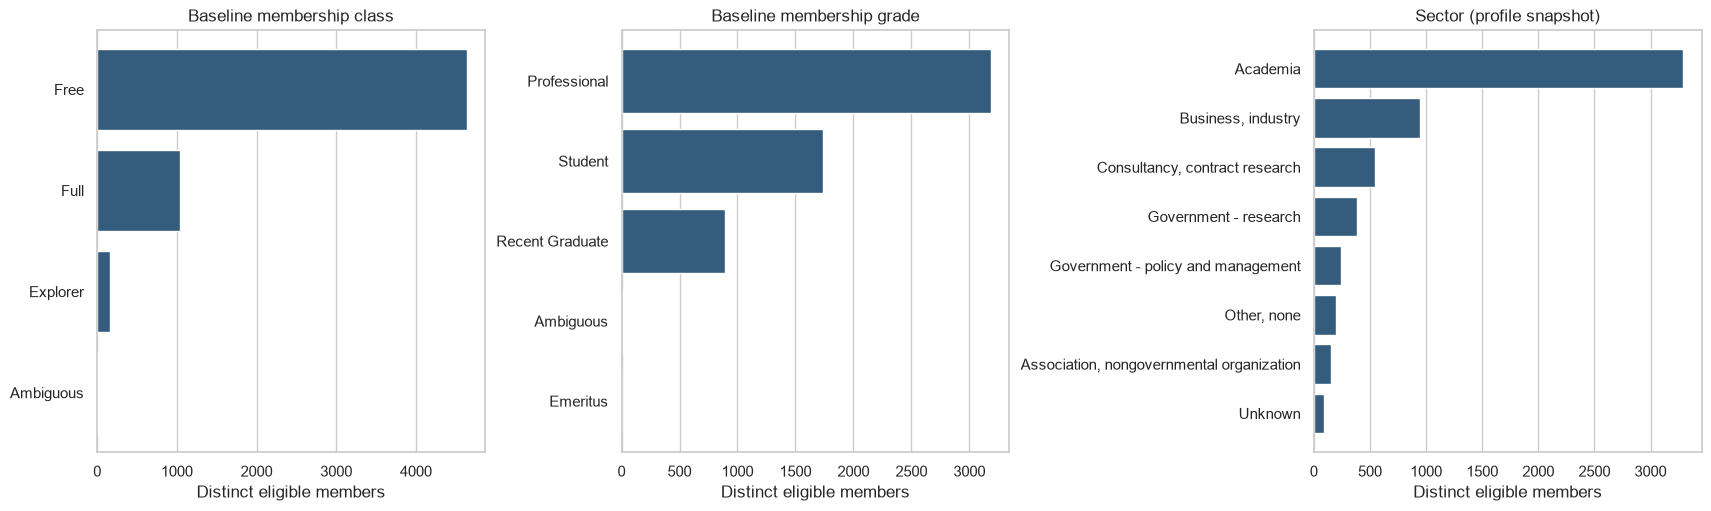

In [149]:
def member_breakdown(frame, column):
    result = frame[column].fillna('Unknown').value_counts().rename_axis(column).reset_index(name='members')
    result['percentage'] = 100 * result['members'] / len(frame)
    return result

class_breakdown = member_breakdown(members, 'member_class_baseline')
payment_breakdown = member_breakdown(members, 'paid_or_free_baseline')
grade_breakdown = member_breakdown(members, 'grade_baseline')
sector_breakdown = member_breakdown(members, 'sector')
display(class_breakdown.round(1))
display(payment_breakdown.round(1))
display(grade_breakdown.round(1))
display(sector_breakdown.round(1))

fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for ax, table, column, title in [
    (axes[0], class_breakdown, 'member_class_baseline', 'Baseline membership class'),
    (axes[1], grade_breakdown, 'grade_baseline', 'Baseline membership grade'),
    (axes[2], sector_breakdown, 'sector', 'Sector (profile snapshot)')
]:
    ax.barh(table[column].astype(str), table['members'], color='#355c7d')
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel('Distinct eligible members')
    ax.grid(axis='y', visible=False)
plt.show()


Section 3 Observations
- Which membership class is largest? Give the count and percentage.
- How large is the student segment compared with other grades?
- Which sectors dominate the member base? Keeping the original sector labels for now.
- How many members have changing or conflicting class/grade records? How might that affect a simple paid/free comparison?
- Avoid calling Retired or currently not working a confirmed retirement category. This notebook keeps the recorded subscription grade instead of Busola's derived Retired override.
Initial observations from master file: The population contains 5,835 members.
    -  At their first covered day in the window, 4,635 (79.4%) are Free, 1,035 (17.7%) are Full and 156 (2.7%) are Explorer.
    -  Nine members have an ambiguous baseline class and remain separate.
    -  Students account for 1,741 members (29.8%), compared with 3,185 Professionals (54.6%) and 891 Recent Graduates (15.3%).
    -  The retained terms show class variation for 176 people and grade variation for 230, so the baseline labels should not be interpreted as fixed throughout the year. These are first-run figures; *will recheck them if the inputs or rules change.*

4. Import and profile the webinar files
Each source filename becomes a webinar identifier. We retain the exact filename, while using W01, W02, etc. as short chart labels. These labels refer to the supplied file collection and are not SETAC's official event IDs.

We read all supplied webinar/Café exports before selecting dates. The catalogue shows which ones contribute to our year and whether they provide an attendance field. It should not be read as a complete calendar of webinars offered by SETAC.

In [150]:
webinar_frames = []
source_audit = []

def collect_webinar(frame, filename):
    required = {'Contact ID', 'Date booked'}
    if not required.issubset(frame.columns):
        raise ValueError(f'{filename}: missing {required - set(frame.columns)}')
    source_audit.append({
        'source_file': filename, 'raw_rows': len(frame),
        'has_attendance_field': 'Attended' in frame.columns
    })
    frame = frame.copy()
    frame['source_file'] = filename
    frame['source_row'] = np.arange(2, len(frame) + 2)
    webinar_frames.append(frame)

if WEBINAR_DIR is not None:
    webinar_files = sorted(
        p for p in Path(WEBINAR_DIR).iterdir()
        if p.suffix.lower() == '.xlsx' and not p.name.startswith(('~$', '._'))
    )
    for path in webinar_files:
        collect_webinar(pd.read_excel(path), path.name)
else:
    with zipfile.ZipFile(RAW_ZIP_PATH) as archive:
        paths = sorted(
            name for name in archive.namelist()
            if '/Events/Webinars/' in name and name.lower().endswith('.xlsx')
            and '__MACOSX' not in name and not Path(name).name.startswith(('~$', '._'))
        )
        for name in paths:
            collect_webinar(pd.read_excel(BytesIO(archive.read(name))), Path(name).name)

if not webinar_frames:
    raise ValueError('No webinar files found.')

webinar_raw = pd.concat(webinar_frames, ignore_index=True, sort=False)
source_audit = pd.DataFrame(source_audit)
webinar_raw['contact_id'] = clean_contact_id(webinar_raw['Contact ID'])
webinar_raw['booking_date'] = pd.to_datetime(webinar_raw['Date booked'], errors='coerce')
webinar_raw['booking_status'] = (
    webinar_raw['Status'].astype('string').str.strip().fillna('Unknown')
    if 'Status' in webinar_raw else 'Unknown'
)
webinar_raw['in_window'] = (
    webinar_raw['booking_date'].ge(ANALYSIS_START)
    & webinar_raw['booking_date'].lt(ANALYSIS_END_EXCLUSIVE)
)
webinar_catalogue = webinar_raw.groupby('source_file', as_index=False).agg(
    first_booking=('booking_date', 'min'), last_booking=('booking_date', 'max'),
    bookings_in_window=('in_window', 'sum')
).merge(source_audit, on='source_file', validate='one_to_one')
webinar_catalogue['webinar_id'] = [f'W{i:02}' for i in range(1, len(webinar_catalogue) + 1)]
webinar_catalogue['webinar_title'] = (
    webinar_catalogue['source_file'].str.replace(r'\.xlsx$', '', regex=True)
    .str.replace(r'(?i)^webinar[_ ]*', '', regex=True)
    .str.replace(r'_attendees$', '', regex=True).str.replace('_', ' ', regex=False)
)
webinar_raw = webinar_raw.merge(
    webinar_catalogue[['source_file', 'webinar_id']], on='source_file',
    how='left', validate='many_to_one'
)
print(f'Supplied webinar/Café files: {len(webinar_catalogue)}')
print(f'Files with bookings in the year: {webinar_catalogue.bookings_in_window.gt(0).sum()}')
display(webinar_catalogue[['webinar_id', 'webinar_title', 'raw_rows',
                          'first_booking', 'last_booking', 'bookings_in_window',
                          'has_attendance_field']])
display(webinar_raw['booking_status'].value_counts(dropna=False).reset_index(name='rows'))


Supplied webinar/Café files: 20
Files with bookings in the year: 4


,webinar_id,webinar_title,raw_rows,first_booking,last_booking,bookings_in_window,has_attendance_field
0,W01,agricultural biologics unpacked science and regulation,144,2026-03-09 18:50:29,2026-04-21 18:05:29,144,False
1,W02,criteria for reporting and evaluating exposure datasets creed general overview,180,2024-02-08 21:46:02,2024-03-14 03:15:46,0,False
2,W03,defining safer drawing a line in the sand to advance substitution,141,2025-04-03 16:29:38,2025-04-24 16:18:30,0,False
3,W04,driving safer chemicals through alternatives assessment,128,2024-02-21 11:23:53,2024-04-02 23:28:30,0,False
4,W05,eco transcriptomics data usability recommended minimum reporting information,89,2026-01-14 21:46:43,2026-02-24 21:11:08,89,False
5,W06,ecosystem salinization challenges and next steps,126,2024-12-23 20:32:25,2025-02-25 16:03:54,0,False
6,W07,freshwater mussel biology and laboratory toxicity testing webinar,121,2023-07-20 15:59:48,2023-08-23 12:53:07,0,False
7,W08,how to use creed,77,2024-03-11 09:30:01,2024-04-17 17:34:18,0,False
8,W09,immunotoxicology for ecotoxicologists simply adding a few more assays,271,2024-08-05 18:10:41,2024-10-07 11:21:16,0,False
9,W10,incorporating climate change model projections into ecological risk assessments t...,119,2023-09-22 14:27:20,2023-10-19 12:11:31,0,False


,booking_status,rows
0,Confirmed,2289


4.1 Select usable registrations and check repeated bookings

The primary measure uses Confirmed bookings made within the window and with a usable Contact ID. Other statuses, missing dates and missing IDs remain visible in the audit.

If one contact appears twice in one webinar file, counts them once for that webinar. Retains the earliest confirmed booking for this exploratory registration measure and reports the removed repetitions. 
This does not prove the repeated source rows were errors.
Trying here not to deduplicate someone across different webinar files.

In [151]:
confirmed = webinar_raw['booking_status'].str.casefold().eq('confirmed').fillna(False)
usable = webinar_raw['in_window'] & confirmed & webinar_raw['contact_id'].notna()
registrations_all = webinar_raw.loc[usable].copy()
registrations_all = registrations_all.sort_values(['booking_date', 'source_file', 'source_row'])
repeated_bookings = registrations_all.loc[
    registrations_all.duplicated(['contact_id', 'webinar_id'], keep='first')
].copy()
registrations = registrations_all.drop_duplicates(['contact_id', 'webinar_id'], keep='first').copy()
registrations['registration_id'] = np.arange(1, len(registrations) + 1)

webinar_checks = pd.DataFrame({
    'check': ['All source rows', 'Rows with unparseable/missing booking date',
              'All rows booked within the year', 'Within-year rows missing Contact ID',
              'Within-year rows not Confirmed', 'Repeated confirmed contact–webinar rows',
              'Distinct confirmed contact–webinar registrations in year'],
    'count': [len(webinar_raw), webinar_raw.booking_date.isna().sum(),
              webinar_raw.in_window.sum(),
              (webinar_raw.in_window & webinar_raw.contact_id.isna()).sum(),
              (webinar_raw.in_window & ~confirmed).sum(),
              len(repeated_bookings), len(registrations)]
})
display(webinar_checks)
display(webinar_catalogue.loc[webinar_catalogue.bookings_in_window.gt(0),
                              ['webinar_id', 'webinar_title', 'bookings_in_window']])


,check,count
0,All source rows,2289
1,Rows with unparseable/missing booking date,0
2,All rows booked within the year,667
3,Within-year rows missing Contact ID,0
4,Within-year rows not Confirmed,0
5,Repeated confirmed contact–webinar rows,0
6,Distinct confirmed contact–webinar registrations in year,667


,webinar_id,webinar_title,bookings_in_window
0,W01,agricultural biologics unpacked science and regulation,144
4,W05,eco transcriptomics data usability recommended minimum reporting information,89
10,W11,metals regulations from around the world,151
15,W16,case study evaluating potential endocrine disruption from oecd s new guidance on ...,283


Section 4 Observations
- State how many supplied files actually contribute bookings in the year.
    - Only four of the 20 exports contain bookings in this year. They concern Agricultural Biologics, Eco-transcriptomics, Metals Regulations and an Endocrine Disruption case study. 
    - Together they provide 667 confirmed contact–webinar registrations within the booking-date window. None of the supplied Café exports contributes bookings in this period. 
    - This is a small, topic-specific collection, so absence from it is not sufficient evidence of low overall engagement.
- We may have to expad our analysis period, one year is too small to look at it seems.
- Need to record missing IDs, unconfirmed bookings and repeated contact–webinar registrations.
- A quiet month may simply have no supplied webinar file. Do not assume SETAC offered no webinars, or that members disengaged that month. This is jsut a snapshot look at the year period of 1 October 2025 to 30 September 2026 (instead of our initial 1 September ‘25 to 31 August ‘26)


5. Link registrations to the Theme 3 population

First matches Contact IDs to the member list. A registration outside our cohort is labelled outside the eligible Europe cohort, not automatically a non-member: it could belong to another geographic unit, an excluded profile or someone whose coverage differs from our rules.

Then checks membership coverage on the booking day. We preserve registrations made outside recorded coverage in a separate audit. Our primary registration count requires both cohort membership and recorded coverage on the booking date.

The temporary registration-to-term merge can contain multiple rows per booking. We collapse it back to one registration before counting. This prevents overlapping subscription terms from inflating webinar counts. Conflicting class/grade matches are flagged.

In [152]:
registrations['in_theme3_population'] = registrations['contact_id'].isin(members['contact_id'])
cohort_bookings = registrations.loc[registrations.in_theme3_population].copy()
outside_population_bookings = registrations.loc[~registrations.in_theme3_population].copy()

candidate_matches = cohort_bookings.merge(
    period_terms[['contact_id', 'coverage_start', 'coverage_end_exclusive',
                  'member_class', 'grade_short']],
    on='contact_id', how='left', validate='many_to_many'
)
booking_day = candidate_matches['booking_date'].dt.normalize()
covered_matches = candidate_matches.loc[
    booking_day.ge(candidate_matches['coverage_start'])
    & booking_day.lt(candidate_matches['coverage_end_exclusive'])
].copy()

booking_attributes = covered_matches.groupby('registration_id', as_index=False).agg(
    matching_terms=('member_class', 'size'),
    member_class_at_booking=('member_class', one_value_or_ambiguous),
    grade_at_booking=('grade_short', one_value_or_ambiguous)
)
cohort_bookings = cohort_bookings.merge(
    booking_attributes, on='registration_id', how='left', validate='one_to_one'
)
cohort_bookings['covered_at_booking'] = cohort_bookings['matching_terms'].notna()
outside_coverage_bookings = cohort_bookings.loc[~cohort_bookings.covered_at_booking].copy()
eligible_registrations = cohort_bookings.loc[cohort_bookings.covered_at_booking].copy()
eligible_registrations['paid_or_free_at_booking'] = (
    eligible_registrations['member_class_at_booking'].map(
        {'Free': 'Free', 'Full': 'Paid', 'Explorer': 'Paid', 'Ambiguous': 'Ambiguous'}
    ).fillna('Unknown')
)

linkage_summary = pd.DataFrame({
    'check': ['All confirmed contact–webinar registrations in window',
              'Outside eligible Europe cohort', 'Cohort bookings outside recorded coverage',
              'Primary eligible registrations', 'Distinct eligible registrants',
              'Eligible bookings with multiple matching terms',
              'Eligible bookings with ambiguous class'],
    'count': [len(registrations), len(outside_population_bookings),
              len(outside_coverage_bookings), len(eligible_registrations),
              eligible_registrations.contact_id.nunique(),
              eligible_registrations.matching_terms.gt(1).sum(),
              eligible_registrations.member_class_at_booking.eq('Ambiguous').sum()]
})
display(linkage_summary)
assert (len(registrations) == len(outside_population_bookings)
        + len(outside_coverage_bookings) + len(eligible_registrations))
assert not eligible_registrations.duplicated(['contact_id', 'webinar_id']).any()


,check,count
0,All confirmed contact–webinar registrations in window,667
1,Outside eligible Europe cohort,442
2,Cohort bookings outside recorded coverage,17
3,Primary eligible registrations,208
4,Distinct eligible registrants,204
5,Eligible bookings with multiple matching terms,0
6,Eligible bookings with ambiguous class,0


5.1 Builds one analysis row per member, including zero registrations

We summarise webinar registrations before merging into the member table. This gives each member equal weight when calculating membership proportions and participation rates.

webinars_registered means different supplied webinars with an eligible booking in the year. Zero means no eligible registration found in this supplied collection, not no SETAC engagement of any kind.

Initial linkage results: Of 667 within-window registrations, 442 fall outside the eligible Europe cohort. Another 17 belong to cohort members but were booked outside their recorded subscription coverage. The primary measure therefore uses 208 registrations from 204 people. This classification does not establish that the other contacts were non-members. They may belong to other geographic units or fall outside our retained records. No eligible booking has multiple matching membership terms in this first run.

In [153]:
member_webinars = eligible_registrations.groupby('contact_id', as_index=False).agg(
    webinars_registered=('webinar_id', 'nunique'),
    first_booking_in_window=('booking_date', 'min'),
    last_booking_in_window=('booking_date', 'max')
)
analysis = members.merge(member_webinars, on='contact_id', how='left', validate='one_to_one')
analysis['webinars_registered'] = analysis['webinars_registered'].fillna(0).astype(int)
analysis['registered_any_webinar'] = analysis['webinars_registered'].gt(0)
analysis['registered_multiple_webinars'] = analysis['webinars_registered'].ge(2)
analysis['coverage_group'] = pd.cut(
    analysis['covered_days'], bins=[0, 90, 180, 270, WINDOW_DAYS],
    labels=['1–90 days', '91–180 days', '181–270 days', f'271–{WINDOW_DAYS} days']
)
assert len(analysis) == len(members) and analysis['contact_id'].is_unique
assert analysis['webinars_registered'].sum() == len(eligible_registrations)

overview = pd.DataFrame({
    'measure': ['Eligible members', 'Members with an eligible webinar registration',
                'Registration rate (%)', 'Members registering for 2+ supplied webinars',
                'Mean registrations per eligible member, including zeros',
                'Mean registrations among registrants only'],
    'value': [len(analysis), analysis.registered_any_webinar.sum(),
              100 * analysis.registered_any_webinar.mean(),
              analysis.registered_multiple_webinars.sum(),
              analysis.webinars_registered.mean(),
              analysis.loc[analysis.registered_any_webinar, 'webinars_registered'].mean()]
})
display(overview.round(3))


,measure,value
0,Eligible members,5835.000
1,Members with an eligible webinar registration,204.000
2,Registration rate (%),3.496
3,Members registering for 2+ supplied webinars,3.000
4,"Mean registrations per eligible member, including zeros",0.036
5,Mean registrations among registrants only,1.020
